# 🔍 Pelican-VLA 0.5: Attention & Perception Explanation
### Session: `20261015T162257+0700_797af814`
**Task:** `serving brewed coffee` (Astribot S1)

Notebook này giải thích cơ chế chú ý (visual attention) của mô hình Pelican-VLA 0.5 tại các chu kỳ infer trong session:
1. Load và hiển thị Attention Heatmaps cho 3 camera (`cam_head`, `cam_left_wrist`, `cam_right_wrist`).
2. So sánh chu kỳ bình thường (`cycle_000003`) và chu kỳ có chuyển động bất thường (`cycle_000015`).
3. Đánh giá mức độ tập trung vào đối tượng (object-centric attention) qua bottleneck tokens.
4. Hỗ trợ chạy giải thích (explain) trực tiếp cho bất kỳ chu kỳ nào khác.

In [1]:
import os
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Thiết lập đường dẫn
REPO_ROOT = Path('/home/anhnb9/Documents/Pelican-VLA05')
SESSION_DIR = REPO_ROOT / 'logs/sessions/20261015T162257+0700_797af814'
EXPLANATION_DIR = REPO_ROOT / 'explanations/20261015T162257+0700_797af814'

print(f"Session path: {SESSION_DIR.resolve()}")
print(f"Explanation path: {EXPLANATION_DIR.resolve()}")
assert SESSION_DIR.exists(), "Session directory not found!"
assert EXPLANATION_DIR.exists(), "Explanation directory not found!" 

Session path: /home/anhnb9/Documents/Pelican-VLA05/logs/sessions/20261015T162257+0700_797af814
Explanation path: /home/anhnb9/Documents/Pelican-VLA05/explanations/20261015T162257+0700_797af814


## 1. Kiểm tra các thư mục giải thích đã sinh sẵn
Kiểm tra các cycle đã được chạy offline qua `scripts/explain_session.py`:

In [2]:
existing_expls = sorted([p for p in EXPLANATION_DIR.iterdir() if p.is_dir()])
print(f"Đã có {len(existing_expls)} thư mục giải thích trong session này:")
for p in existing_expls:
    print(f" - {p.name}")

Đã có 2 thư mục giải thích trong session này:
 - cycle_000003_rollout_step0_dim0
 - cycle_000015_rollout_step0_dim0


## 2. Hàm trực quan hóa Attention Heatmap đa góc nhìn
Hàm dưới đây load ảnh RGB gốc và Attention Heatmap từ file `.npz` và `.png` của 3 camera để so sánh trực quan:

In [3]:
def plot_cycle_attention(expl_path):
    expl_path = Path(expl_path)
    meta_file = expl_path / 'metadata.json'
    meta = json.loads(meta_file.read_text()) if meta_file.exists() else {}
    
    cameras = ['cam_head', 'cam_left_wrist', 'cam_right_wrist']
    fig, axes = plt.subplots(2, 3, figsize=(15, 9), dpi=120)
    fig.suptitle(f"Attention Analysis: {expl_path.name}\n"
                 f"Replay Raw Error: {meta.get('replay_max_absolute_error', 'N/A'):.4e} | "
                 f"Normalized Error: {meta.get('replay_max_normalized_error', 'N/A'):.4e}",
                 fontsize=14, fontweight='bold', y=0.98)
    
    for col_idx, cam in enumerate(cameras):
        npz_file = expl_path / f'{cam}.npz'
        png_file = expl_path / f'{cam}.png'
        
        if npz_file.exists():
            data = np.load(npz_file)
            rgb = data['rgb']
            heat = data['heat']
            
            # Hàng 1: Ảnh RGB gốc
            axes[0, col_idx].imshow(rgb)
            axes[0, col_idx].set_title(f"Original RGB: {cam}", fontsize=11, fontweight='semibold')
            axes[0, col_idx].axis('off')
            
            # Hàng 2: Heatmap Overlay
            if png_file.exists():
                overlay = Image.open(png_file)
                axes[1, col_idx].imshow(overlay)
            else:
                axes[1, col_idx].imshow(rgb)
                im = axes[1, col_idx].imshow(heat, cmap='turbo', alpha=0.5)
                plt.colorbar(im, ax=axes[1, col_idx], fraction=0.046, pad=0.04)
                
            axes[1, col_idx].set_title(f"Attention Overlay: {cam}", fontsize=11, fontweight='semibold')
            axes[1, col_idx].axis('off')
        else:
            axes[0, col_idx].text(0.5, 0.5, f"Missing {cam}", ha='center')
            axes[1, col_idx].text(0.5, 0.5, f"Missing {cam}", ha='center')
            
    plt.tight_layout()
    plt.show()

## 3. Trực quan hóa Cycle 3 (Chu kỳ suy luận ổn định)
Xem cách Pelican-VLA phân bổ sự chú ý lên quai cốc / tách cà phê và tay robot:

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


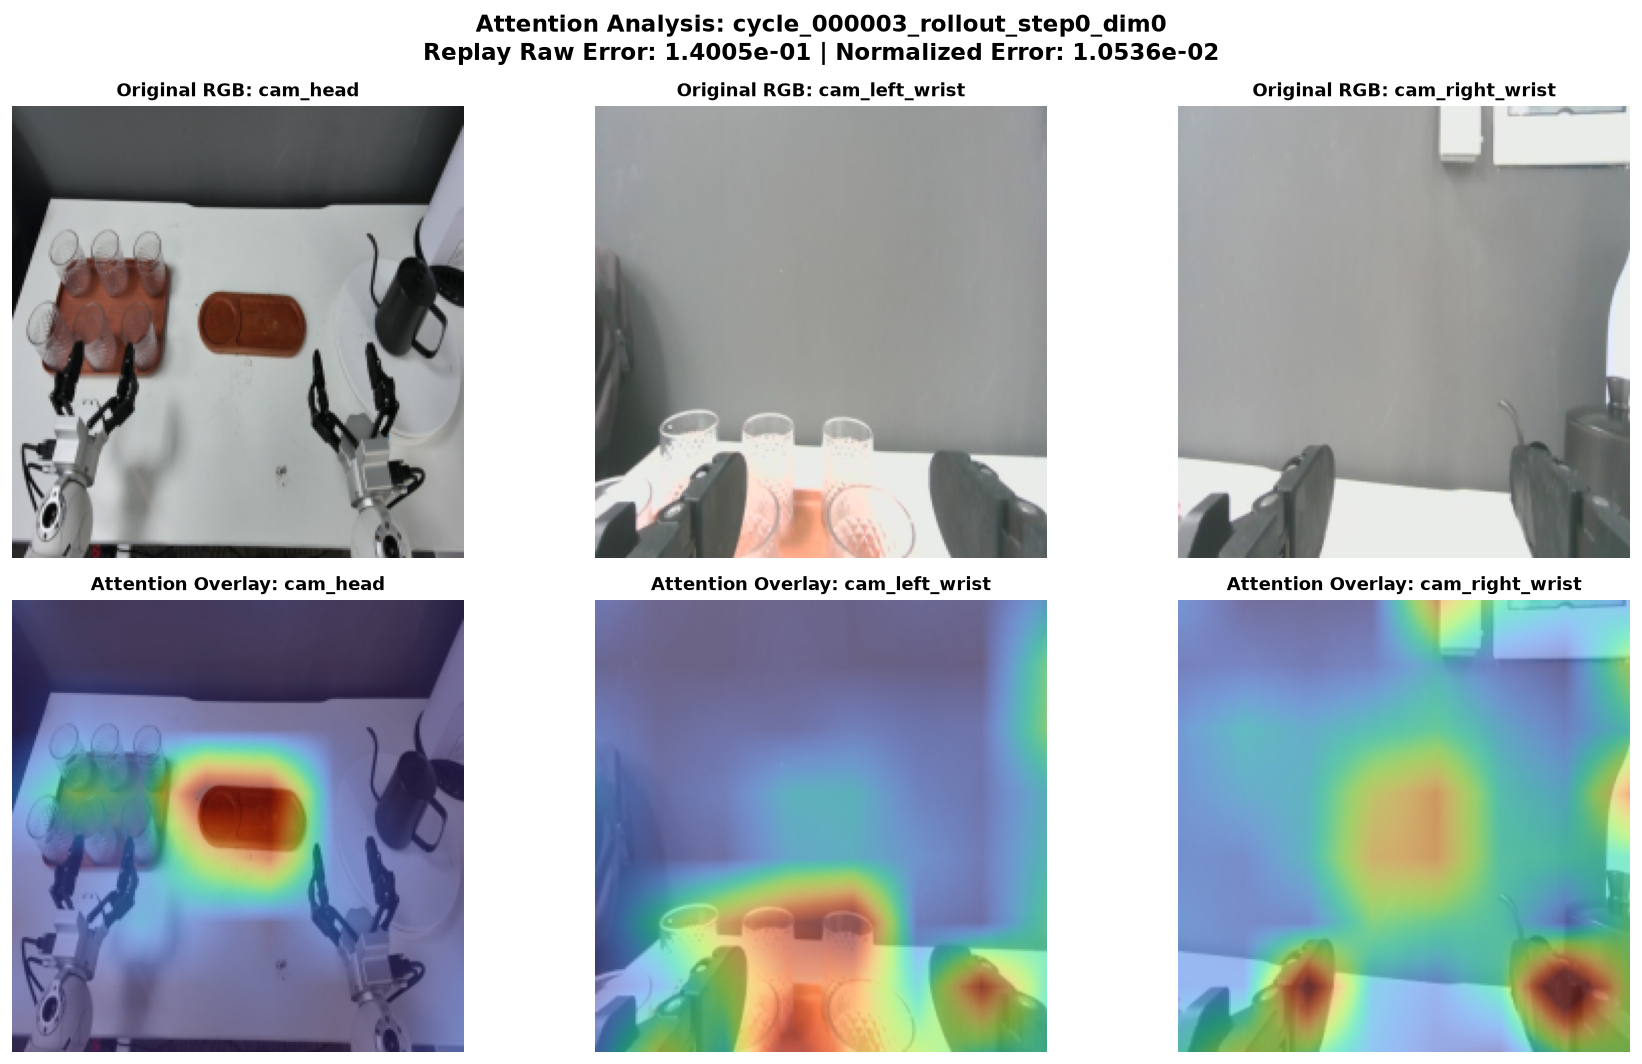

In [4]:
c3_path = EXPLANATION_DIR / 'cycle_000003_rollout_step0_dim0'
if c3_path.exists():
    plot_cycle_attention(c3_path)
else:
    print(f"Chưa có {c3_path}. Bạn có thể sinh bằng lệnh ở mục 5.")

## 4. Trực quan hóa Cycle 15 (Chu kỳ có nhảy khớp cánh tay `raw_arm_jump=0.145rad`)
Tại cycle 15, robot ghi nhận cú nhảy góc khớp cánh tay lớn nhất và xuất hiện cảnh báo bám quỹ đạo (`WARNING tracking: max=0.172rad joint=3`).
Hãy xem sự chú ý của mô hình tại thời điểm này:

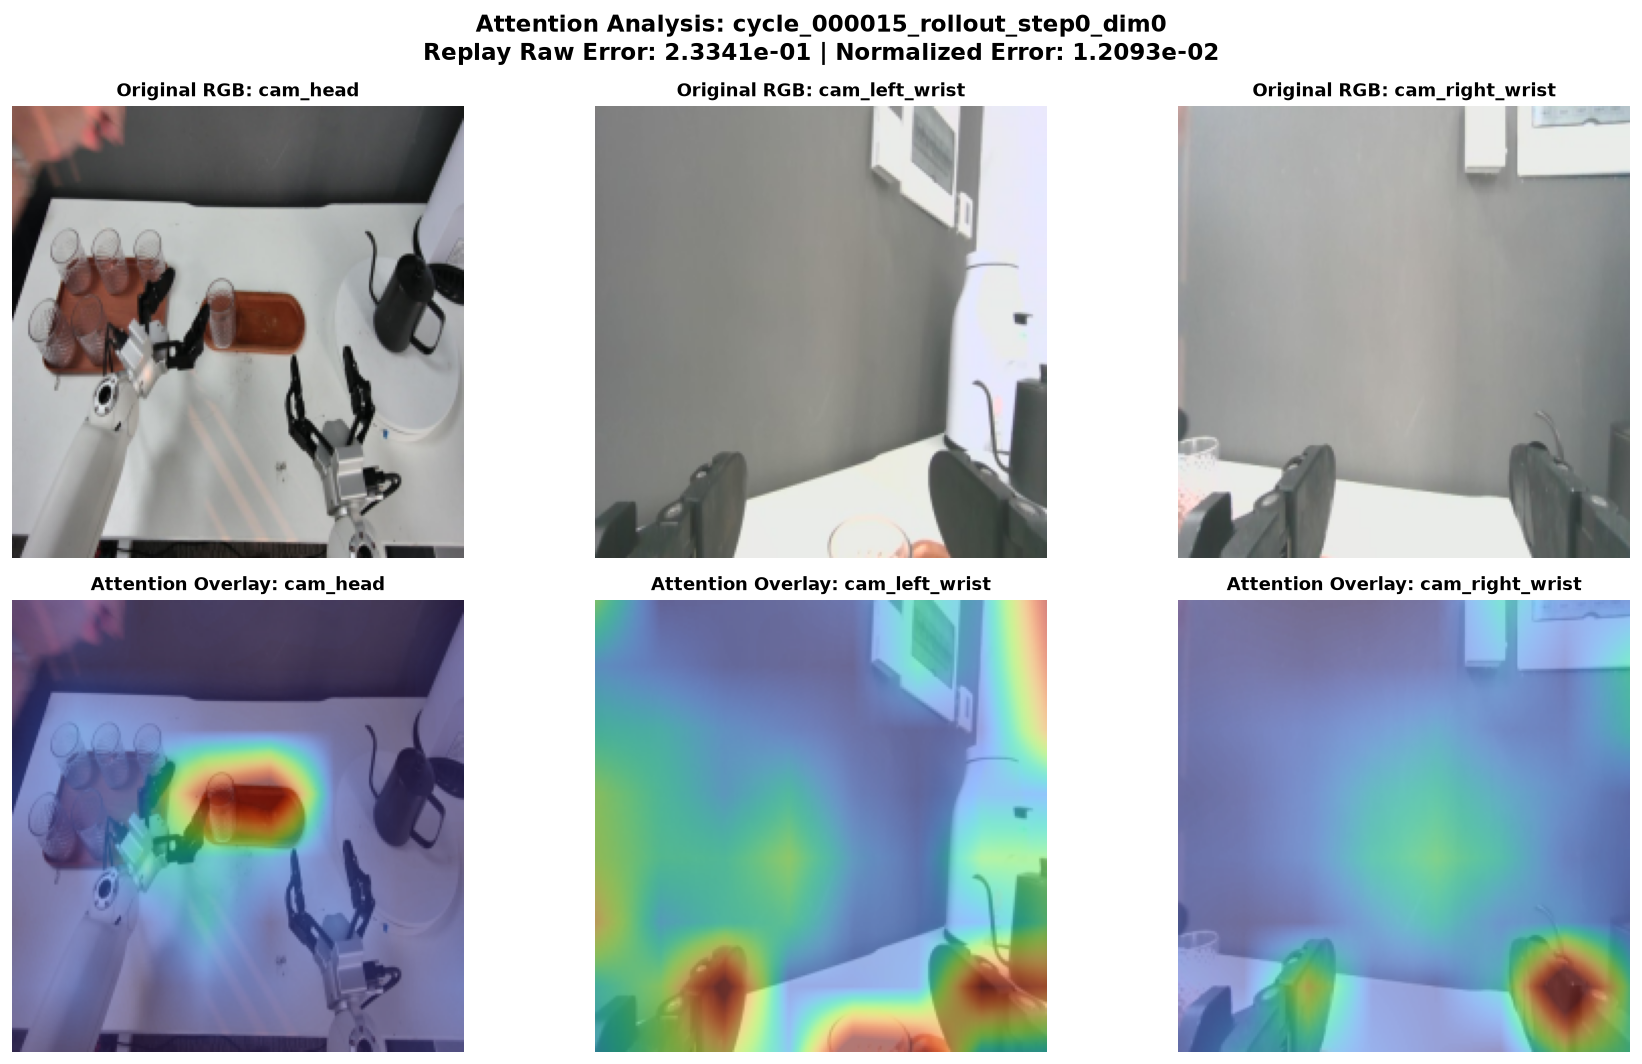

In [5]:
c15_path = EXPLANATION_DIR / 'cycle_000015_rollout_step0_dim0'
if c15_path.exists():
    plot_cycle_attention(c15_path)
else:
    print(f"Chưa có {c15_path}. Bạn có thể sinh bằng lệnh ở mục 5.")

## 5. Phân tích định lượng độ tập trung Attention (Attention Distribution)
Đo lường mức độ tập trung (Entropy và Peak Percentile) của sự chú ý trên từng camera để xem camera nào mang nhiều thông tin điều khiển nhất:

In [6]:
def analyze_attention_concentration(expl_path):
    expl_path = Path(expl_path)
    cameras = ['cam_head', 'cam_left_wrist', 'cam_right_wrist']
    results = {}
    
    for cam in cameras:
        npz_file = expl_path / f'{cam}.npz'
        if not npz_file.exists():
            continue
        data = np.load(npz_file)
        heat = data['heat']
        # Chuẩn hóa về xác suất
        p = heat / (heat.sum() + 1e-12)
        # Shannon entropy: entropy càng thấp -> sự chú ý càng tập trung vào 1 vùng nhỏ
        entropy = -float(np.sum(p * np.log(p + 1e-12)))
        p99 = float(np.percentile(heat, 99))
        p90 = float(np.percentile(heat, 90))
        max_val = float(heat.max())
        
        results[cam] = {
            'entropy': entropy,
            'max': max_val,
            'p99': p99,
            'concentration_ratio (p99/mean)': float(p99 / (heat.mean() + 1e-12))
        }
    return results

print("--- Cycle 3 Attention Concentration ---")
print(json.dumps(analyze_attention_concentration(c3_path), indent=2))

print("\n--- Cycle 15 Attention Concentration ---")
print(json.dumps(analyze_attention_concentration(c15_path), indent=2))

--- Cycle 3 Attention Concentration ---
{
  "cam_head": {
    "entropy": 10.165658950805664,
    "max": 0.033477846533060074,
    "p99": 0.02896972931921482,
    "concentration_ratio (p99/mean)": 6.832886695861816
  },
  "cam_left_wrist": {
    "entropy": 10.43691635131836,
    "max": 0.014369050040841103,
    "p99": 0.012373561039566994,
    "concentration_ratio (p99/mean)": 3.678706407546997
  },
  "cam_right_wrist": {
    "entropy": 10.673433303833008,
    "max": 0.008396973833441734,
    "p99": 0.005976414307951927,
    "concentration_ratio (p99/mean)": 2.804292917251587
  }
}

--- Cycle 15 Attention Concentration ---
{
  "cam_head": {
    "entropy": 10.247593879699707,
    "max": 0.04674088954925537,
    "p99": 0.03441012278199196,
    "concentration_ratio (p99/mean)": 7.523393154144287
  },
  "cam_left_wrist": {
    "entropy": 10.642913818359375,
    "max": 0.009814813733100891,
    "p99": 0.007460490800440311,
    "concentration_ratio (p99/mean)": 2.944519519805908
  },
  "cam_r

## 6. Tiện ích: Sinh giải thích cho bất kỳ Cycle nào khác
Bạn có thể gọi hàm sau để sinh giải thích offline bằng GPU cho một cycle bất kỳ (ví dụ `cycle=16`):

In [7]:
import subprocess

def run_explain_cycle(cycle_num, method='rollout', action_step=0, action_dim=0, device='cuda:0'):
    cmd = [
        '/home/anhnb9/miniconda3/envs/pelican_vla/bin/python',
        str(REPO_ROOT / 'scripts/explain_session.py'),
        str(SESSION_DIR),
        f'--cycle={cycle_num}',
        f'--method={method}',
        f'--action-step={action_step}',
        f'--action-dim={action_dim}',
        f'--device={device}'
    ]
    print(f"Đang chạy: {' '.join(cmd)}")
    res = subprocess.run(cmd, capture_output=True, text=True)
    if res.returncode == 0:
        print("✅ Thành công!")
        out_line = [l for l in res.stdout.strip().split('\n') if 'cycle_' in l][-1]
        print(f"Output lưu tại: {out_line}")
        plot_cycle_attention(out_line)
    else:
        print("❌ Lỗi:")
        print(res.stderr)

# Ví dụ bỏ comment dòng dưới để chạy cho cycle 16:
# run_explain_cycle(16)